In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "netflix_cleaned_dataset.csv"
df = pd.read_csv(data_path)
print("Loaded:", df.shape)

Loaded: (8790, 10)


In [10]:
country_titles = (
    df[["show_id", "country"]]
    .copy()
    .assign(country=lambda data: data["country"].astype("string").str.split(", "))
    .explode("country")
)

country_titles["country"] = country_titles["country"].str.strip()
unknown_labels = {"", "unknown country", "unknown", "not given", "na", "n/a"}
is_unknown = country_titles["country"].str.lower().isin(unknown_labels)
country_titles.loc[is_unknown, "country"] = pd.NA

country_titles = (
    country_titles
    .dropna(subset=["country"])
    .drop_duplicates(subset=["show_id", "country"])
    .reset_index(drop=True)
)

print("Title-country rows:", len(country_titles))
print("Countries represented:", country_titles["country"].nunique())
print("Titles with no usable country:", df["country"].astype("string").str.strip().str.lower().isin(unknown_labels).sum())
display(country_titles.head())

Title-country rows: 8503
Countries represented: 85
Titles with no usable country: 287


,show_id,country
0,s1,United States
1,s3,France
2,s6,United States
3,s14,Brazil
4,s8,United States


In [11]:
country_counts = (
    country_titles
    .groupby("country")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(country_counts.head(10))

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: show_id, dtype: int64

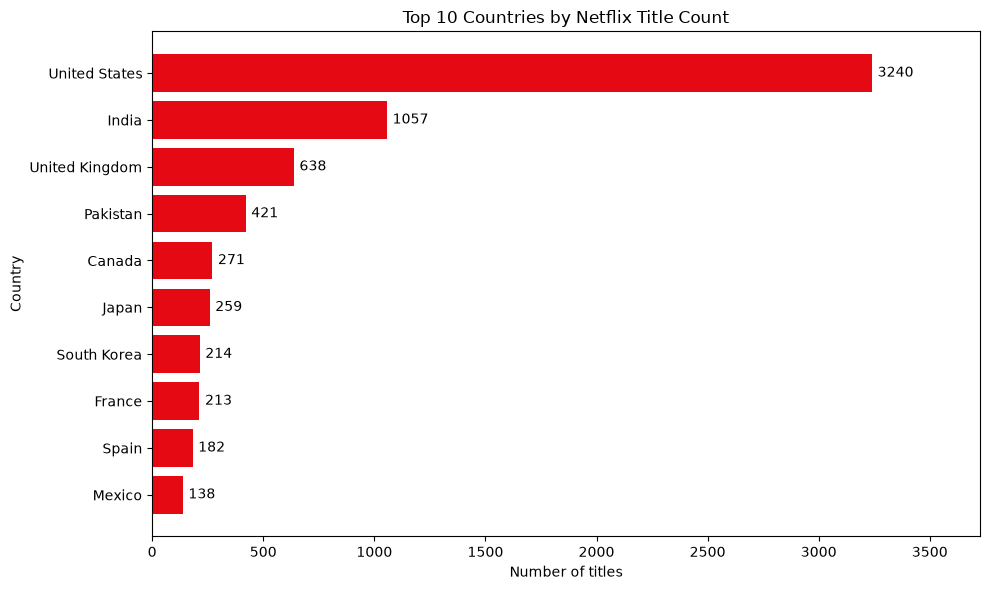

In [12]:
# ranking chart
top_countries = country_counts.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_countries.index, top_countries.values, color="#E50914")

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_title("Top 10 Countries by Netflix Title Count")
ax.set_xlabel("Number of titles")
ax.set_ylabel("Country")
ax.set_xlim(0, top_countries.max() * 1.15)

fig.tight_layout()
plt.show()

# Key findings

- **Top country credits:** The United States has the most titles associated with it (3,240), followed by India (1,057) and the United Kingdom (638).
- **Comparison:** The United States count is about 3.1 times India's.

These counts reflect recorded country credits, not regional availability or viewer demand. Titles credited to multiple countries are counted for each country, and 287 titles with unknown country were excluded.